#### Importing Modules

In [58]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import random
import os
from PIL import Image
import warnings
warnings.filterwarnings('ignore')
import keras 
import tensorflow as tf 
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,Dense,Flatten,GlobalAveragePooling2D,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau,ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

In [59]:
tf.config.optimizer.set_jit(False)

#### Setting Seed

In [60]:
SEED=42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

#### Setting Constants

In [61]:
DATASET_DIR=r"D:\Flowers Recognition\flowers"
LABEL_MAP={}
for i,class_name in enumerate(os.listdir(DATASET_DIR)):
    LABEL_MAP[class_name]=i
print(LABEL_MAP)
IMG_SIZE=(224,224)
BATCH_SIZE=64

{'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


#### Reading Files

In [62]:
image_paths=[]
labels=[]
for class_name,class_label in LABEL_MAP.items():
    class_path=os.path.join(DATASET_DIR,class_name)
    for file in os.listdir(class_path):
        file_path=os.path.join(class_path,file)
        image_paths.append(file_path)
        labels.append(class_label)
print(f"Sample Image Path: {image_paths[4]} and Label: {labels[4]}")

Sample Image Path: D:\Flowers Recognition\flowers\daisy\10172636503_21bededa75_n.jpg and Label: 0


#### Creating DataFrame

In [63]:
df=pd.DataFrame({
    'image':image_paths,
    'label':labels
})
df.head()

,image,label
0,D:\Flowers Recognition\flowers\daisy\100080576...,0
1,D:\Flowers Recognition\flowers\daisy\101403031...,0
2,D:\Flowers Recognition\flowers\daisy\101723795...,0
3,D:\Flowers Recognition\flowers\daisy\101725674...,0
4,D:\Flowers Recognition\flowers\daisy\101726365...,0


#### Shuffling DataFrame

In [64]:
df=df.sample(frac=1,random_state=SEED)
df.head()

,image,label
3800,D:\Flowers Recognition\flowers\tulip\210550417...,4
2014,D:\Flowers Recognition\flowers\rose\1846405239...,2
1923,D:\Flowers Recognition\flowers\rose\1569950905...,2
2533,D:\Flowers Recognition\flowers\rose\8241471746...,2
3747,D:\Flowers Recognition\flowers\tulip\198685095...,4


In [65]:
print("Total Number of images:",len(df),"images")

Total Number of images: 4317 images


#### Checking Corrupted Images

In [66]:
valid_images=[]
for image in df['image']:
    try:
        with Image.open(image) as img:
            img.verify()
        valid_images.append(image)
    except Exception:
        print("Invalid Image: ", image)
print(f"Valid Images: {len(valid_images)} out of {len(df)} images.")

Valid Images: 4317 out of 4317 images.


#### Removing invalid Images

In [67]:
df=df[df['image'].isin(valid_images)].reset_index(drop=True)
df.head()

,image,label
0,D:\Flowers Recognition\flowers\tulip\210550417...,4
1,D:\Flowers Recognition\flowers\rose\1846405239...,2
2,D:\Flowers Recognition\flowers\rose\1569950905...,2
3,D:\Flowers Recognition\flowers\rose\8241471746...,2
4,D:\Flowers Recognition\flowers\tulip\198685095...,4


#### Visualizing Random Images

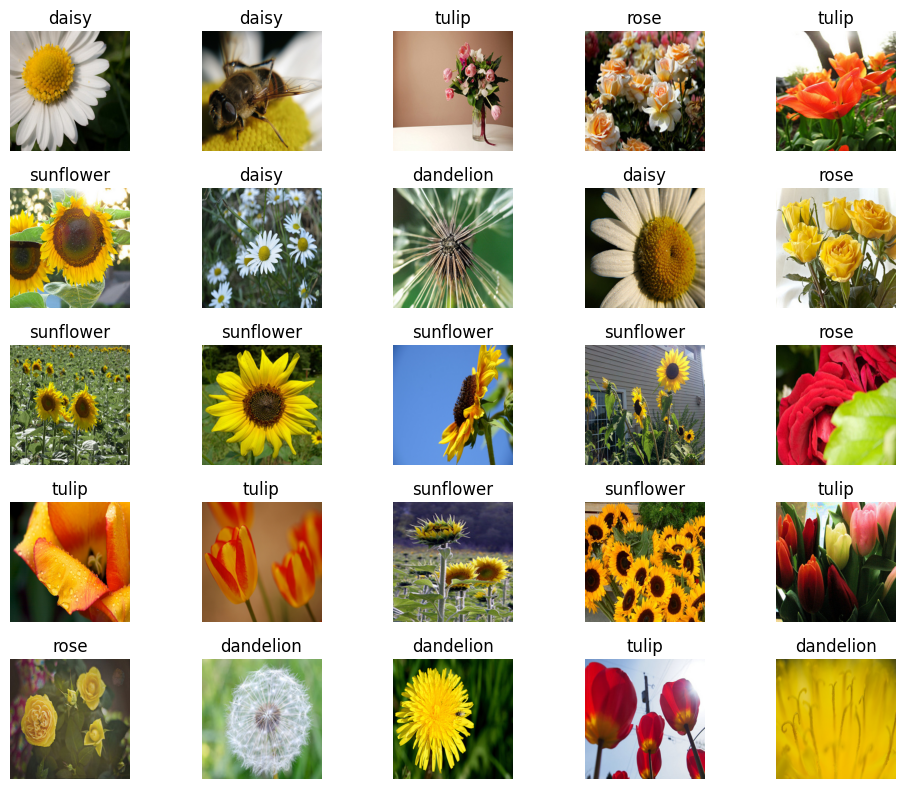

In [68]:
plt.figure(figsize=(10,8))
sample_df=df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    label=row['label']
    plt.subplot(5,5,i+1)
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(image)
    plt.title({v:k for k,v in LABEL_MAP.items()}[label])
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Fixing Datatypes

In [69]:
df['label']=df['label'].astype(str)
df.head()

,image,label
0,D:\Flowers Recognition\flowers\tulip\210550417...,4
1,D:\Flowers Recognition\flowers\rose\1846405239...,2
2,D:\Flowers Recognition\flowers\rose\1569950905...,2
3,D:\Flowers Recognition\flowers\rose\8241471746...,2
4,D:\Flowers Recognition\flowers\tulip\198685095...,4


#### Creating Splits

In [70]:
train_df,temp_df=train_test_split(df,test_size=0.3,random_state=SEED,stratify=df['label'])
val_df,test_df=train_test_split(temp_df,test_size=0.5,random_state=SEED,stratify=temp_df['label'])
print(f"Train size: {len(train_df)} images.")
print(f"Val size: {len(val_df)} images.")
print(f"Test size: {len(test_df)} images.")

Train size: 3021 images.
Val size: 648 images.
Test size: 648 images.


#### Creating Generators

In [71]:
train_data_generator=ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='reflect'
)

In [72]:
val_test_data_generator=ImageDataGenerator(
    preprocessing_function=preprocess_input
)

#### Creating Iterators

In [73]:
train_iterator=train_data_generator.flow_from_dataframe(
    train_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

Found 3021 validated image filenames belonging to 5 classes.


In [74]:
val_iterator=val_test_data_generator.flow_from_dataframe(
    val_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 648 validated image filenames belonging to 5 classes.


In [75]:
test_iterator=val_test_data_generator.flow_from_dataframe(
    test_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 648 validated image filenames belonging to 5 classes.


#### Visualizing Images Before and After Augmentation

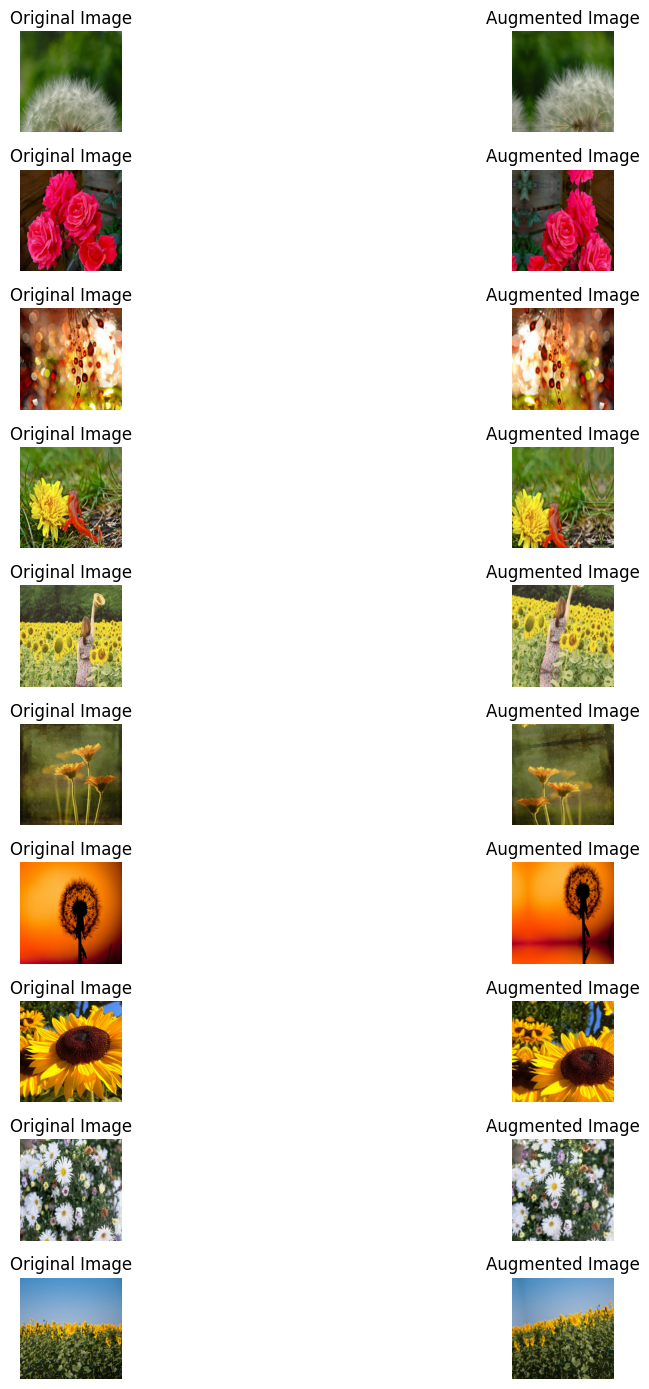

In [76]:
plt.figure(figsize=(14,14))
sample_df2=train_df.sample(10,random_state=SEED)
for i,(_,row) in enumerate(sample_df2.iterrows()):
    image_path=row['image']
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    image=np.array(image)
    augmented_image=train_data_generator.random_transform(image)    
    plt.subplot(10,2,2*i+1)
    plt.imshow(image)
    plt.axis('off')
    plt.title("Original Image")
    plt.subplot(10,2,2*i+2)
    plt.imshow(augmented_image)
    plt.title("Augmented Image")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Model

In [77]:
base_model=EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE,3)
)
base_model.trainable=False
model=Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(64,activation='relu'),
    Dropout(0.3),
    Dense(len(LABEL_MAP),activation='softmax')
])

In [78]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,131,880 (15.76 MB)

 Trainable params: 82,309 (321.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [79]:
opt=keras.optimizers.Adam(learning_rate=1e-2)
model.compile(loss='categorical_crossentropy',optimizer=opt,metrics=['accuracy'])

In [80]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    patience=3,
    factor=0.2,
    min_lr=1e-4
)

In [81]:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [82]:
checkpoint=ModelCheckpoint(
    "best_transfer_learning_model2.keras",
    monitor='val_loss',
    save_best_only=True
)

In [83]:
history=model.fit(train_iterator,epochs=15,validation_data=val_iterator,callbacks=[lr_scheduler,early_stop,checkpoint])

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 181s 3s/step - accuracy: 0.7911 - loss: 0.5706 - val_accuracy: 0.8997 - val_loss: 0.2979 - learning_rate: 0.0100
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 135s 3s/step - accuracy: 0.8838 - loss: 0.3203 - val_accuracy: 0.9244 - val_loss: 0.2619 - learning_rate: 0.0100
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 141s 3s/step - accuracy: 0.9014 - loss: 0.2761 - val_accuracy: 0.9167 - val_loss: 0.2922 - learning_rate: 0.0100
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 129s 3s/step - accuracy: 0.9133 - loss: 0.2497 - val_accuracy: 0.9275 - val_loss: 0.2727 - learning_rate: 0.0100
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - accuracy: 0.9321 - loss: 0.1936 - val_accuracy: 0.9151 - val_loss: 0.3005 - learning_rate: 0.0100
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.9480 - loss: 0.1477 - val_accuracy: 0.9244 - val_loss: 0.2957 - learning_rate: 0.0020
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.9537 - loss: 0.1324 - val_accu

#### Evaluating Model on Test Data

In [84]:
test_results=model.evaluate(test_iterator,return_dict=True)
print(test_results)

11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 929ms/step - accuracy: 0.9090 - loss: 0.3030
{'accuracy': 0.9089506268501282, 'loss': 0.3029641807079315}


#### Accuracy and Loss Curves

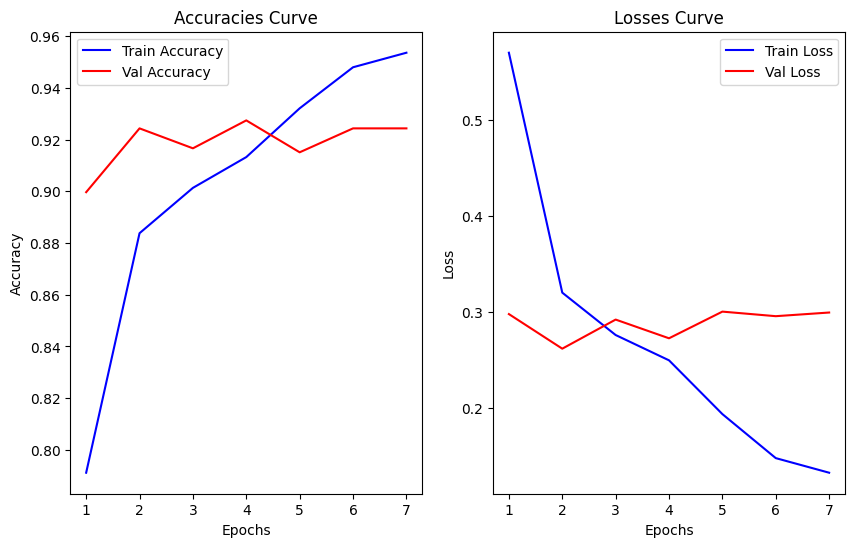

In [85]:
plt.figure(figsize=(10,6))
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
train_loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(train_acc)+1)
plt.subplot(1,2,1)
plt.plot(epochs,train_acc,'b',label="Train Accuracy")
plt.plot(epochs,val_acc,'r',label="Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracies Curve")
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs,train_loss,'b',label="Train Loss")
plt.plot(epochs,val_loss,'r',label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Losses Curve")
plt.legend()
plt.show()

#### Confusion Matrix

11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step 


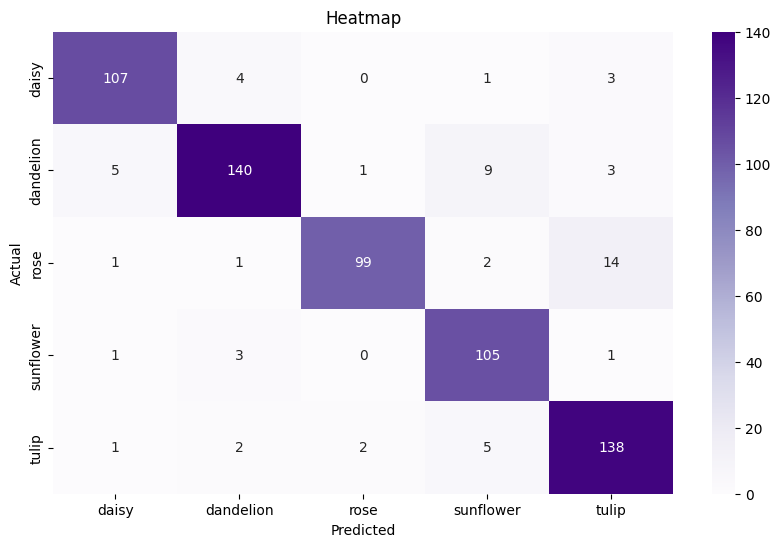

In [86]:
plt.figure(figsize=(10,6))
class_indices = list(range(len(LABEL_MAP)))
class_names = list(LABEL_MAP.keys())
y_true=test_iterator.classes
y_pred=np.argmax(model.predict(test_iterator),axis=1)
cm=confusion_matrix(y_true,y_pred,labels=class_indices)
sns.heatmap(cm,annot=True,fmt='d',cmap="Purples",xticklabels=class_names,yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heatmap")
plt.show()

#### Classification Report

In [87]:
print(classification_report(y_true,y_pred,labels=class_indices,target_names=class_names))

              precision    recall  f1-score   support

       daisy       0.93      0.93      0.93       115
   dandelion       0.93      0.89      0.91       158
        rose       0.97      0.85      0.90       117
   sunflower       0.86      0.95      0.91       110
       tulip       0.87      0.93      0.90       148

    accuracy                           0.91       648
   macro avg       0.91      0.91      0.91       648
weighted avg       0.91      0.91      0.91       648



#### Visualizing Random Sample

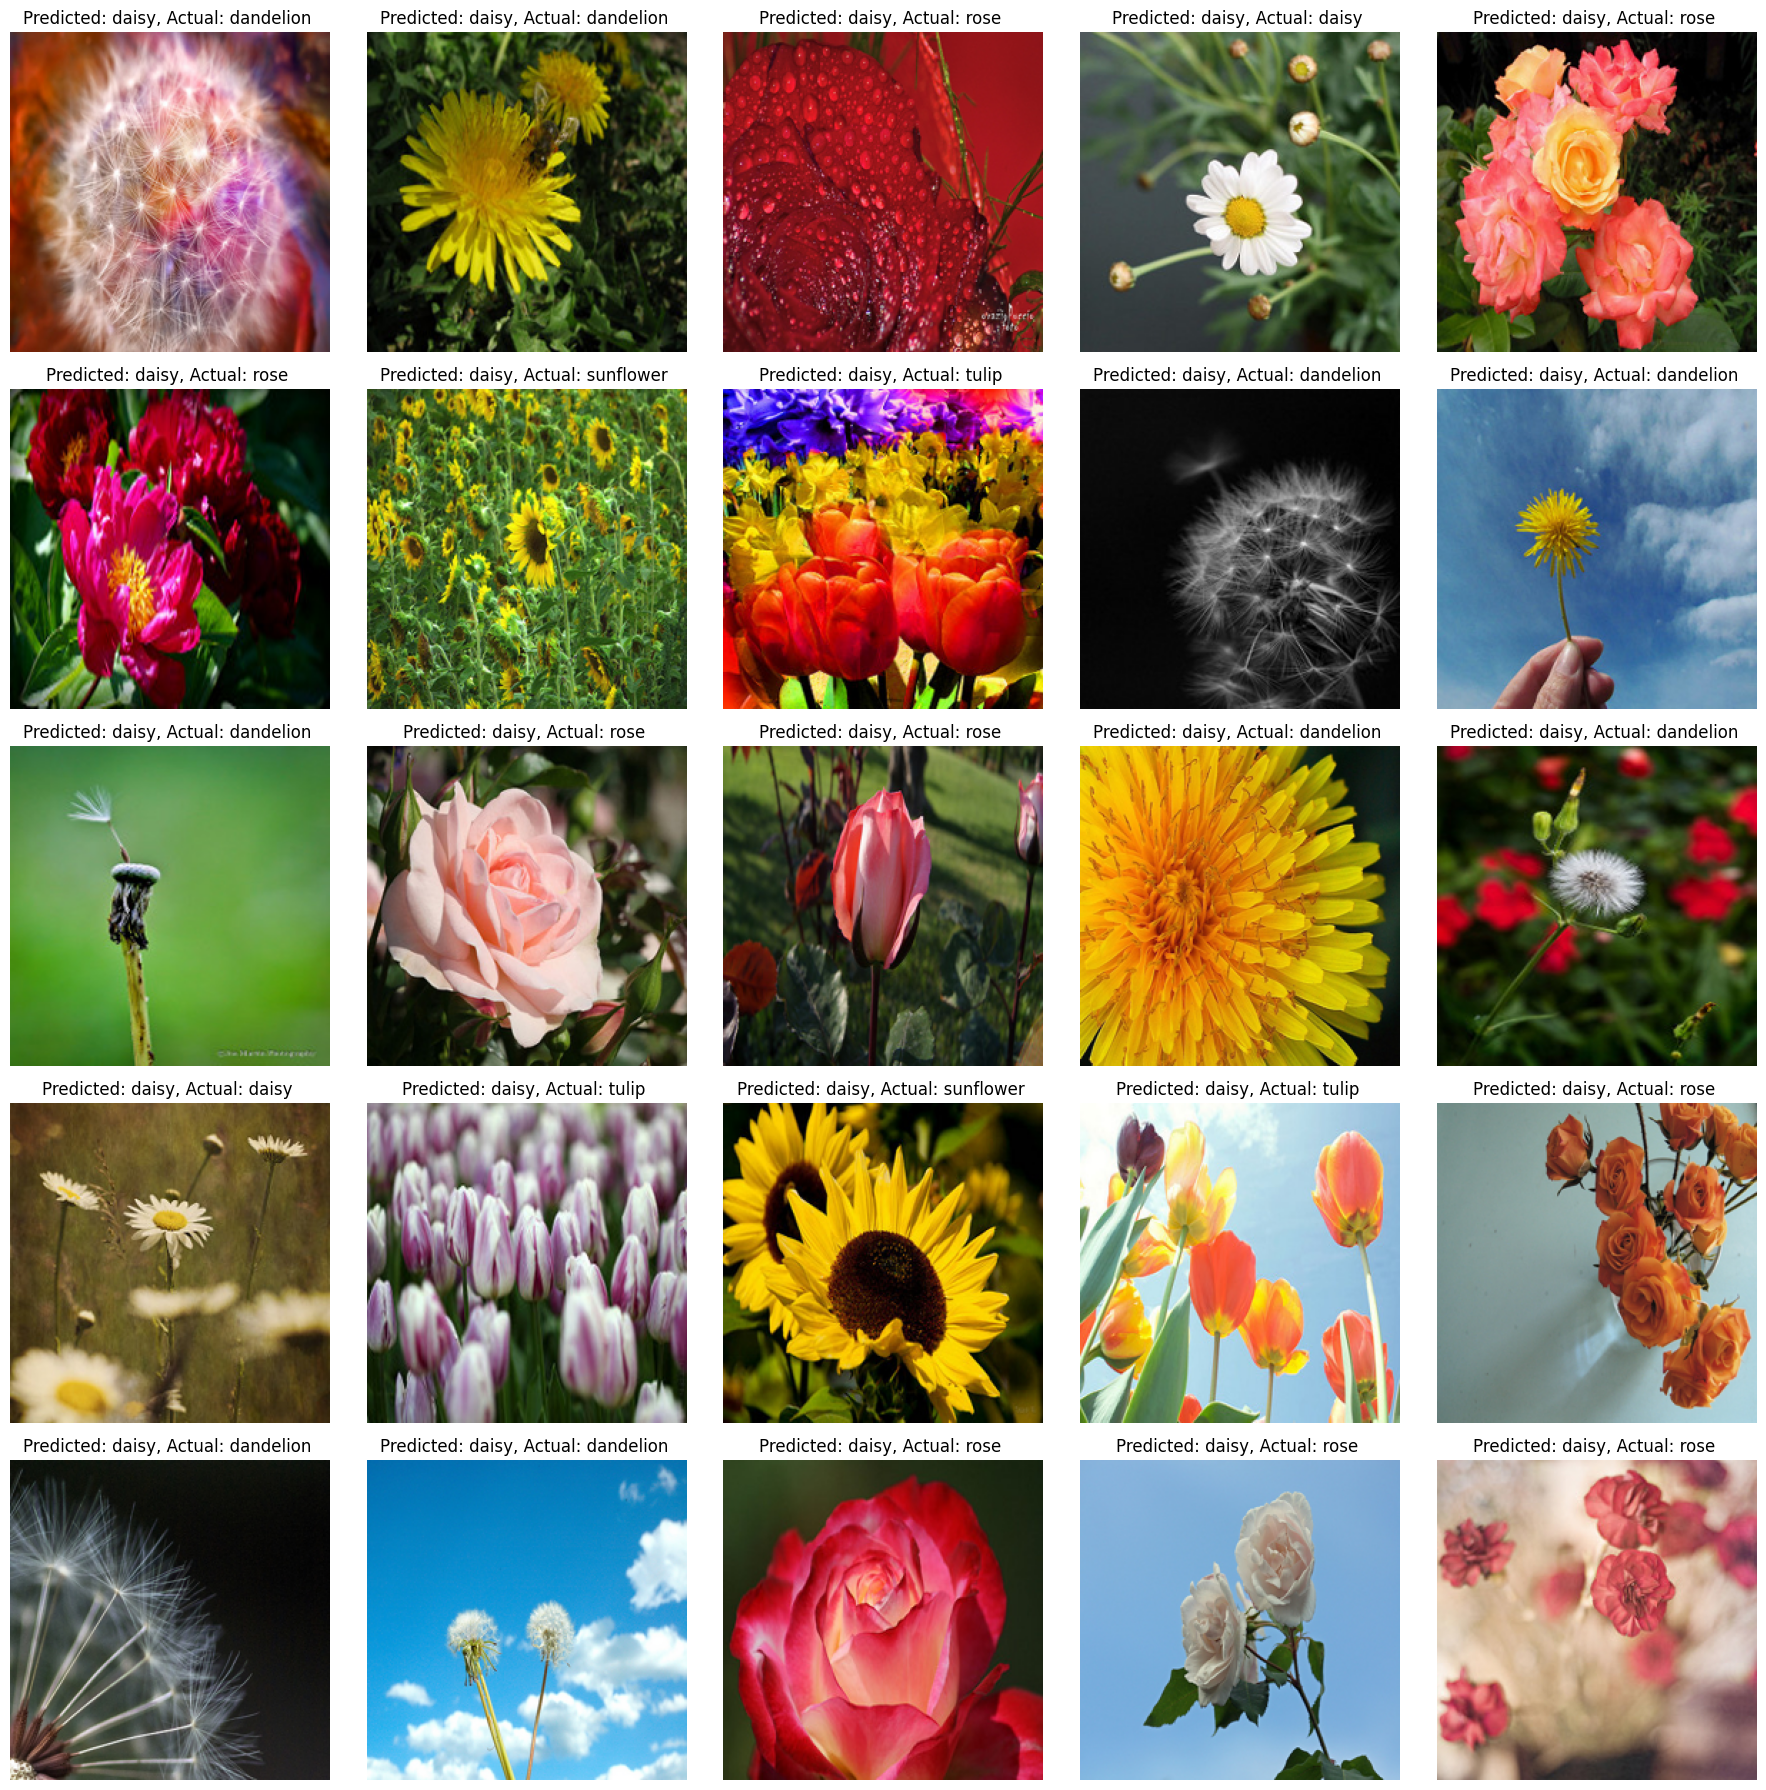

In [88]:
plt.figure(figsize=(18,18))
sample_df=test_df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    true_label=row['label']
    plt.subplot(5,5,i+1)
    image=Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    plt.imshow(image)
    image=np.array(image,dtype=np.float32)
    image=image/255.0
    image=np.expand_dims(image,axis=0)
    pred=model.predict(image,verbose=0)
    pred=np.argmax(pred[0])
    idx_to_class = {v: k for k, v in LABEL_MAP.items()}
    plt.title( f"Predicted: {idx_to_class[pred]}, Actual: {idx_to_class[int(true_label)]} ")
    plt.axis('off')
plt.tight_layout()
plt.show()